# Введение в Pytorch


В этом курсе мы по большей части будем пользоваться pytorch.
Этот фреймворк во многом похож на numpy, главное его отличие в том, что он может считать градиенты с помощью своего autograd модуля. Еще одно отличие - он поддерживает cuda (и другие бэкенды) для повышения производительности.

# Основные операции

In [1]:
%matplotlib inline
import numpy as np
import torch
from matplotlib import pyplot as plt


In [2]:
a = np.random.rand(5, 3)
a

array([[0.26393404, 0.59165486, 0.16851657],
       [0.87276806, 0.58723598, 0.36595071],
       [0.27697759, 0.11575225, 0.10648925],
       [0.74340712, 0.49486117, 0.20889849],
       [0.49976326, 0.35593331, 0.52677872]])

In [3]:
a + 5

array([[5.26393404, 5.59165486, 5.16851657],
       [5.87276806, 5.58723598, 5.36595071],
       [5.27697759, 5.11575225, 5.10648925],
       [5.74340712, 5.49486117, 5.20889849],
       [5.49976326, 5.35593331, 5.52677872]])

In [4]:
a ** 2

array([[0.06966118, 0.35005547, 0.02839783],
       [0.76172408, 0.3448461 , 0.13391992],
       [0.07671659, 0.01339858, 0.01133996],
       [0.55265414, 0.24488758, 0.04363858],
       [0.24976331, 0.12668852, 0.27749582]])

In [5]:
a.shape

(5, 3)

In [6]:
a.flatten()

array([0.26393404, 0.59165486, 0.16851657, 0.87276806, 0.58723598,
       0.36595071, 0.27697759, 0.11575225, 0.10648925, 0.74340712,
       0.49486117, 0.20889849, 0.49976326, 0.35593331, 0.52677872])

In [7]:
a.reshape(-1, 1)

array([[0.26393404],
       [0.59165486],
       [0.16851657],
       [0.87276806],
       [0.58723598],
       [0.36595071],
       [0.27697759],
       [0.11575225],
       [0.10648925],
       [0.74340712],
       [0.49486117],
       [0.20889849],
       [0.49976326],
       [0.35593331],
       [0.52677872]])

In [8]:
b = np.random.rand(7, 5)

In [9]:
a.T @ b.T


array([[1.69088189, 0.86666881, 1.67189264, 1.10472061, 0.78508296,
        0.72183418, 1.52257204],
       [1.36245573, 0.60630078, 1.22384653, 0.79339395, 0.8030079 ,
        0.48866344, 1.19045857],
       [0.85370409, 0.51748418, 0.89549558, 0.58514974, 0.57389934,
        0.53288009, 0.89586749]])

Задача 1: напишите функцию, которая принимает на вход вектор размера n и возвращает значения функции $2log(x^2) - 1.5 sqrt(x) + x^{1/2}$

In [11]:
def f_numpy(x):
    # 2 * log(x^2) - 1.5 * sqrt(x) + x^(1/2). В numpy log - натуральный логарифм.
    x = np.asarray(x, dtype=np.float64)
    return 2 * np.log(x ** 2) - 1.5 * np.sqrt(x) + np.sqrt(x)


f_numpy(np.array([1.0, 4.0, 9.0]))


array([-0.5       ,  4.54517744,  7.28889831])

Задача 2: Посчитайте сумму значений функции из 1 задачи для натуральных чисел с 1 до 300

In [12]:
xs = np.arange(1, 301, dtype=np.float64)
task2_sum = f_numpy(xs).sum()
task2_sum


np.float64(3923.345205492068)

В общем  и целом, синтаксис в torch очень похож на numpy, однако с некоторыми отличиями:

In [24]:
a = torch.rand(5,3)

In [25]:
a**2

tensor([[2.5972e-02, 8.6068e-01, 1.0629e-01],
        [7.4766e-01, 1.7849e-02, 6.7886e-01],
        [4.5895e-01, 1.9509e-01, 1.4675e-01],
        [1.6894e-01, 3.3284e-01, 3.3665e-01],
        [5.7919e-04, 2.7153e-01, 1.5412e-01]])

In [26]:
a.size()

torch.Size([5, 3])

In [27]:
a.flatten()

tensor([0.1612, 0.9277, 0.3260, 0.8647, 0.1336, 0.8239, 0.6775, 0.4417, 0.3831,
        0.4110, 0.5769, 0.5802, 0.0241, 0.5211, 0.3926])

Есть разница между тем, чтобы получить представление тензора или его копию. Самый явный способ получить представление - оператор view. 

In [28]:
b = a.view(-1,1)

In [29]:
b

tensor([[0.1612],
        [0.9277],
        [0.3260],
        [0.8647],
        [0.1336],
        [0.8239],
        [0.6775],
        [0.4417],
        [0.3831],
        [0.4110],
        [0.5769],
        [0.5802],
        [0.0241],
        [0.5211],
        [0.3926]])

In [30]:
a.zero_()

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])

In [31]:
b

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])

In [32]:
a = torch.rand(5,3)

In [33]:
b

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])

In [34]:
a = a.resize(5, 3)

C:\Users\Faste\AppData\Local\Temp\ipykernel_23692\1400543244.py:1: UserWarning: non-inplace resize is deprecated
  a = a.resize(5, 3)


In [35]:
a.view(torch.int)

tensor([[1060113880, 1046079264, 1056870662],
        [1061119905, 1060818181, 1062888351],
        [1027016208, 1037030336, 1058449321],
        [1049126646, 1064549752, 1053897358],
        [1037663064, 1062729325, 1048870254]], dtype=torch.int32)

In [36]:
a

tensor([[0.6877, 0.2128, 0.4972],
        [0.7477, 0.7297, 0.8531],
        [0.0447, 0.1015, 0.5885],
        [0.2664, 0.9521, 0.4086],
        [0.1062, 0.8436, 0.2588]])

In [37]:
b = a.view(3,5)

Тензор устроен чуть сложнее, чем массив numpy. На самом деле он хранит не только данные, но и другую полезную информацию. Например, каждый тензор находится на своем девайсе. 
Вопрос: Если бы тензор находился не на cpu, то перенос его с gpu на cpu создал бы копию?

**Ответ.** Да. Память CPU и GPU — разные адресные пространства, поэтому перенос `cuda -> cpu` (и обратно) всегда выделяет новый блок и копирует числа. Если тензор уже лежит на целевом устройстве и dtype не меняется, `to(device)` возвращает тот же объект.

In [38]:

src = torch.arange(3)
print("cpu -> cpu, тот же объект:", src.to("cpu").data_ptr() == src.data_ptr())
if torch.cuda.is_available():
    on_gpu = src.cuda()
    back = on_gpu.cpu()
    print("gpu -> cpu, новый блок памяти:", back.data_ptr() != on_gpu.data_ptr())
else:
    print("CUDA в этой среде нет. Перенос между устройствами всё равно был бы копией: общая память у них не используется.")


cpu -> cpu, тот же объект: True
CUDA в этой среде нет. Перенос между устройствами всё равно был бы копией: общая память у них не используется.


In [39]:
b.device

device(type='cpu')

In [40]:
a.unsqueeze(0)

tensor([[[0.6877, 0.2128, 0.4972],
         [0.7477, 0.7297, 0.8531],
         [0.0447, 0.1015, 0.5885],
         [0.2664, 0.9521, 0.4086],
         [0.1062, 0.8436, 0.2588]]])

In [41]:
b = torch.rand(7,5)

К тензорам применимы различные операции, как поэлементные, так и матричные.

In [29]:
a.T @ b.T

tensor([[1.0583, 0.3142, 0.8183, 0.6542, 0.6904, 0.2637, 1.2125],
        [2.1442, 2.1260, 1.9849, 1.6937, 1.9315, 1.2295, 2.7025],
        [2.0649, 1.3813, 1.9633, 0.8585, 1.1043, 1.3477, 2.1158]])

In [42]:
torch.matmul(b, a)

tensor([[0.7344, 0.9442, 1.3869],
        [0.4079, 1.4834, 0.6944],
        [1.1253, 1.7864, 1.8329],
        [1.0540, 1.4944, 1.2759],
        [0.7970, 1.1135, 1.1934],
        [0.8584, 0.8003, 1.2934],
        [1.5780, 1.8207, 2.1404]])

In [43]:
b = torch.rand(3,1,4,1,5)

In [44]:
b.squeeze().shape

torch.Size([3, 4, 5])

In [45]:
b.squeeze(1).shape

torch.Size([3, 4, 1, 5])

Задача 3. напишите функцию на torch, которая принимает на вход вектор размера n и возвращает значения функции $2log(x^2) - 1.5 sqrt(x) + x^{1/2}$

In [46]:
def f_torch(x):
    x = torch.as_tensor(x, dtype=torch.float64)
    return 2 * torch.log(x ** 2) - 1.5 * torch.sqrt(x) + torch.sqrt(x)


f_torch(torch.tensor([1.0, 4.0, 9.0], dtype=torch.float64))


tensor([-0.5000,  4.5452,  7.2889], dtype=torch.float64)

Задача 4: Посчитайте сумму значений функции из 3 задачи для натуральных чисел с 1 до 300

In [47]:
xs_t = torch.arange(1, 301, dtype=torch.float64)
task4_sum = f_torch(xs_t).sum()
task4_sum, bool(torch.allclose(task4_sum, torch.tensor(task2_sum, dtype=torch.float64)))


(tensor(3923.3452, dtype=torch.float64), True)

 Другие варианты создать тензор:

In [48]:
a = torch.empty(5,2)
b = torch.zeros(6,1, dtype=torch.bool)
c = torch.ones_like(b) 

Тензор можно создать и из другого объекта. Как думаете, какой тип будет у результирующего тензора?

In [49]:
d = torch.tensor([5,3.4])

In [50]:
d.dtype

torch.float32

**Ответ.** У `torch.tensor([5, 3.4])` тип `torch.float32`. В списке вместе лежат целое и дробное, и PyTorch берёт общий тип, в котором не пропадает дробная часть. Тип по умолчанию для вещественных чисел - float32, поэтому 5 хранится как 5.0. Список из одних целых, `torch.tensor([5, 3])`, получил бы `torch.int64`.

In [51]:

print(torch.tensor([5, 3.4]).dtype)
print(torch.tensor([5, 3]).dtype)


torch.float32
torch.int64


Torch легко переводится в numpy и наоборот. Из-за разницы типов результат не будет идентичным, но он будет достаточно близким к исходному.

In [52]:
a = np.ones((3, 5))
x = torch.ones((3, 5))
np.allclose(x.numpy(), a)

True

Впрочем, если тензор находится на gpu, для начала его необходимо вернуть на cpu. Кроме того, не все типы данных, которые поддерживает torch, например, bf16, поддерживаются numpy, и тогда сначала необходимо привести тензор к нужному типу.

# Градиенты

Одна из основных причин использования PyTorch в глубоком обучении заключается в возможности автоматического получения градиентов для функций практически любой сложности. Мы будем использовать PyTorch преимущественно для реализации нейронных сетей, а они, по сути, представляют собой сложные функции. Если в такой функции используются матрицы коэффициентов, которые мы хотим обучить, то они называются параметрами или просто весами.


Имея на входе данные, мы определяем функцию путем преобразования этих входных данных — как правило, посредством умножения на матрицы весов и сложения с так называемыми векторами смещения (bias vectors). В процессе этих преобразований автоматически формируется вычислительный граф. Этот граф отображает путь от входных данных к выходному результату. PyTorch — это фреймворк, работающий по принципу «define-by-run» (определение в процессе выполнения): это означает, что мы просто выполняем необходимые операции, а PyTorch самостоятельно отслеживает соответствующий граф. Таким образом, в ходе работы создается динамический вычислительный граф. 

Рассмотрим достаточно простой датасет:

In [54]:
x1 = torch.arange(-15, 15, 0.1)
x2 = torch.arange(-15, 15, 0.1) / 5
x = torch.stack([x1, x2], dim=1)
y = x[:,0] * 2. + 0.2 * x[:, 1]**2 - 3 + torch.normal(0., 0.2, (1, 300))

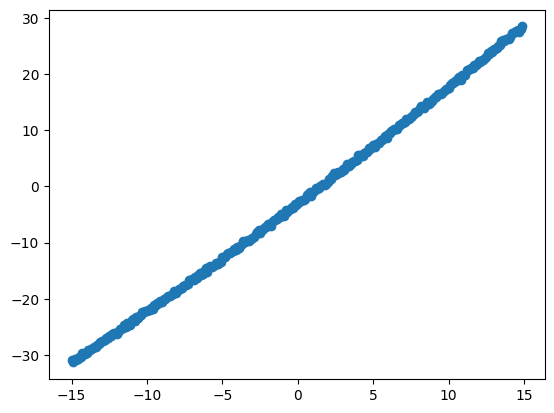

In [55]:
plt.scatter(x[:, 0], y)

Доп.задание. Изобразите поверхность на 3d-графике

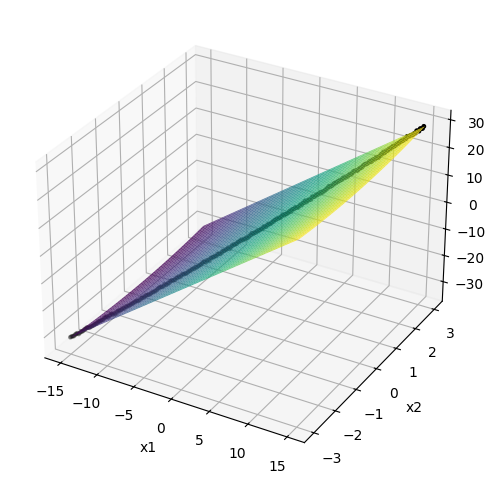

In [43]:

# Поверхность истинной зависимости без шума: y = 2 x1 + 0.2 x2^2 - 3.
# В выборке x2 = x1 / 5, поэтому по второй оси берётся отрезок [-3, 3].
x1_axis = torch.linspace(-15, 15, 80)
x2_axis = torch.linspace(-3, 3, 80)
xx1, xx2 = torch.meshgrid(x1_axis, x2_axis, indexing="xy")
zz = 2 * xx1 + 0.2 * xx2 ** 2 - 3

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(xx1.numpy(), xx2.numpy(), zz.numpy(), cmap="viridis", alpha=0.8)
ax.scatter(x[:, 0].numpy(), x[:, 1].numpy(), y.view(-1).numpy(), s=6, c="k")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
plt.show()



Прежде всего необходимо указать, какие тензоры будут требовать градиенты, с помощью параметра requires_grad. Если requires_grad=False, то это просто массив с числами, посчитать dx/dy не выйдет (по умолчанию).

Если же requires_grad=True, то фреймворк будит учитывать этот тензор при построении графа вычислений производной.
Например, станет возможно посчитать d(sin(log(x**2) - 3x))/dx.


Итак, как PyTorch строит вычислительный граф и вычисляет градиенты? Вершинами графа являются объекты класса torch.autograd.Node, например, AddBackward, MulBackward - это результаты выполнения операций. Ребрами же являются сами тензоры. Соответственно, у каждого тензора,  для которого требуется вычисление градиентов, есть ссылка на функцию .grad_fn, которая градиент создала, и значение самих частных производных (тоже тензор) .grad. Если градиенты неприменимы, то эта функция станет None.



In [57]:
a = torch.rand(5,2, requires_grad=True)
b = torch.rand(2, 1, requires_grad=True)

In [58]:
mult_res = a @ b
res = mult_res.sum()
res

tensor(2.2565, grad_fn=<SumBackward0>)

In [59]:
mult_res

tensor([[0.3829],
        [0.4944],
        [0.4789],
        [0.6665],
        [0.2337]], grad_fn=<MmBackward0>)

In [60]:
mult_res.grad_fn.next_functions

((<AccumulateGrad at 0x279ada57580>, 0),
 (<AccumulateGrad at 0x279adcee710>, 0))

In [61]:
print(a.grad)

None


А как же получить значения градиентов? Тензоры что-то содержат, операции все известны. На самом деле еще при вычислении значения выражения уже известно, какие операции производятся, поэтому и производную можно посчитать. То, как конкретно это делается, вы узнаете на лекции по backpropagation.

In [62]:
res.backward()

In [63]:
b.grad.data

tensor([[1.5775],
        [2.0029]])

In [64]:
mult_res.grad

C:\Users\Faste\AppData\Local\Temp\ipykernel_23692\6217836.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\build\aten\src\ATen/core/TensorBody.h:493.)
  mult_res.grad


Граф перестраивается на каждом проходе. Это удобно - мы не зависим от размеров семпплов и батчей, но дает оверхед, который может стать значительным у больших моделей. 

Начиная с PyTorch 2.0 появилась возможность получать статические вычислительные графы, что позволяет сильно ускорить обучение, об этом детально мы, возможно, поговорим позже. Пока что просто помните, что если вам необходимо ускорить инференс или обучение модели, один из простейших вариантов - использовать torch.compile и статические графы. В таком случае, многие операции на ускорителе можно оптимизировать, а лишние этапы перестройки опустить.


Перейдем к нашим данным. Попробуем обучить простую линейную модель с помощью градиентного спуска.

In [65]:
w = torch.rand(1, 2, requires_grad=True)
b = torch.rand(1, requires_grad=True)
# Линейная регрессия: y ≈ w1 * x1 + w2 * x2 + b.
# w имеет форму (1, 2), x — (N, 2), поэтому w @ x.T даёт (1, N).
y_pred = w @ x.T + b
loss = torch.mean((y_pred - y) ** 2)
loss.backward()


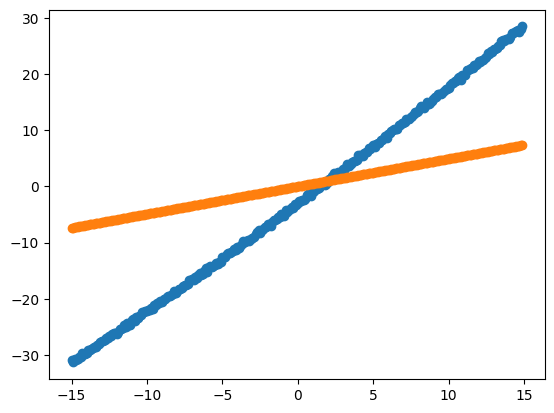

In [66]:
plt.scatter(x[:, 0], y)
plt.scatter(x[:, 0], y_pred.detach().numpy())

Пока не слишком похоже на то, что мы хотим. Для того, чтобы изменения применились, нужно сделать шаг градиентного спуска.

**Задание**. Проведите 100 итераций градиентного спуска для данного набора.
Для этого надо вспомнить, как выглядит этот алгоритм для линейной регрессии

In [67]:
w.grad

tensor([[-226.4983,  -45.2997]])

Weights: tensor([[2.8166, 1.1117]])
Gradients: tensor([[-277.5435,  -55.5087]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.8229, 0.9130]])
Gradients: tensor([[-0.8391, -0.1678]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.8196, 0.9123]])
Gradients: tensor([[1.2940e-04, 2.5950e-05]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.8193, 0.9123]])
Gradients: tensor([[0.0022, 0.0004]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.8192, 0.9123]])
Gradients: tensor([[0.0018, 0.0004]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.8190, 0.9122]])
Gradients: tensor([[0.0015, 0.0003]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.8189, 0.9122]])
Gradients: tensor([[0.0012, 0.0002]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.8188, 0.9122]])
Gradients: tensor([[0.0010, 0.0002]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.8187, 0.9122]])
Gradients: tensor([[0.0008, 0.0002]])
Gradients: tensor([[0., 0.]])
Weights: tensor([[1.8186, 0.9121]])
Gradients: t

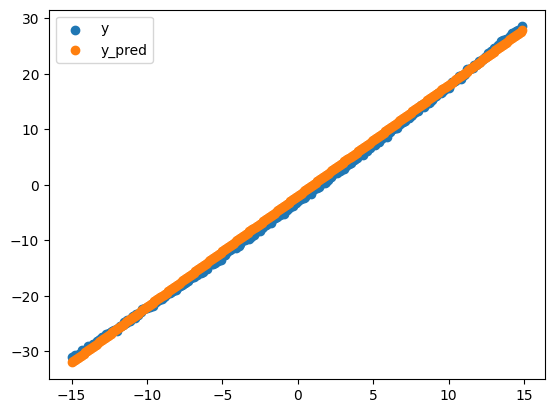

final loss 0.5009217858314514


In [68]:
w = torch.rand(1, 2, requires_grad=True)
b = torch.rand(1, requires_grad=True)

for i in range(100):
    y_pred = w @ x.T + b
    loss = torch.mean((y_pred - y) ** 2)
    loss.backward()
    with torch.no_grad():
        # torch.no_grad() выключает обернутую часть из графа
        # Почему мы не можем сделать так?
        #  w  = w  - 0.1 * w.grad
        #  b  = b  - 0.1 * b.grad
        #
        # Присваивание создаёт новый тензор и перевешивает имя w на него.
        # Внутри no_grad у этого тензора requires_grad=False: это уже не тот
        # leaf, в .grad которого пишет backward. In-place -= меняет данные
        # исходного тензора, и на следующей итерации граф строится по нему же.
        # Шаг 0.1 из комментария расходится: x порядка десятков, градиент
        # большой. Шаг 0.01 для этого набора устойчив.
        lr = 0.01
        w -= lr * w.grad
        b -= lr * b.grad
        if i % 10 == 0 or i == 99:
            print(f"Weights: {w.detach()}")

    if i % 10 == 0 or i == 99:
        print(f"Gradients: {w.grad}")

    # На каждой итерации нужно занулить градиенты
    # - иначе они будут копиться и приведут к непредвиденным результатам
    # Это делают через  grad.data.zero_()
    w.grad.zero_()
    b.grad.zero_()

    if i % 10 == 0 or i == 99:
        print(f"Gradients: {w.grad}")

plt.scatter(x[:, 0], y.view(-1).detach().numpy(), label="y")
plt.scatter(x[:, 0], y_pred.view(-1).detach().numpy(), label="y_pred")
plt.legend()
plt.show()
print("final loss", float(loss.detach()))


# Пайплайн обучения

Кроме собственно тензоров, функций потерь и градиентов, основные составляющие библиотеки как и всегда - датасеты и модели. При этом торч позволяет довольно свободно составлять и то, и другое из простейших блоков, лишь поддерживая необходимые интерфейсы.

Импортируем torch.nn - тут находятся классы, реализующие слои, лоссы, функции ошибок и тд. 
Для примера я использую стандартный датасет для компьютерного зрения - MNIST - содержащий цифры от 0 до 9 в разном написании. Поэтому импортируются некоторые подмодули torchvision


In [69]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt

In [70]:
import os
import pandas as pd
from torchvision.io import read_image


# Создание датасета

Pytorch позволяет использовать открытые датасеты с хаба. Они все являются подклассами `torch.utils.data.Dataset` и имплементируют методы, специфичные для этого класса данных. Обычно они используются для прототипирования и бенчмаркинга и могут быть загружены по необходимости. Однако если для задачи необxодимо что-то кроме предполагаемой разработчиками функциональности, нужно либо отнаследовать один из них, либо напрямую `torch.utils.data.Dataset`.

Давайте загрузим FashionMNIST (https://github.com/zalandoresearch/fashion-mnist) - один из таких простых бенчмарк-датасетов для компьютерного зрения. Каждый семпл - это черно-белое изображение размером 28х28 с каким-то предметом одежды и ассоциированным классом. Всего набор содержит 60000 + 10000 изображений и 10 классов.


In [71]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

In [72]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

In [73]:
def plot_samples(data, labels_map, cols=3, rows=3):
    figure = plt.figure(figsize=(8, 8))
    for i in range(1, cols * rows + 1):
        sample_idx = torch.randint(len(data), size=(1,)).item()
        img, label = data[sample_idx]
        figure.add_subplot(rows, cols, i)
        if type(label) == torch.Tensor:
            plt.title(labels_map[label.item()])
        else:
            plt.title(labels_map[label])
        plt.axis("off")
        plt.imshow(img.squeeze(), cmap="gray")
    plt.show()

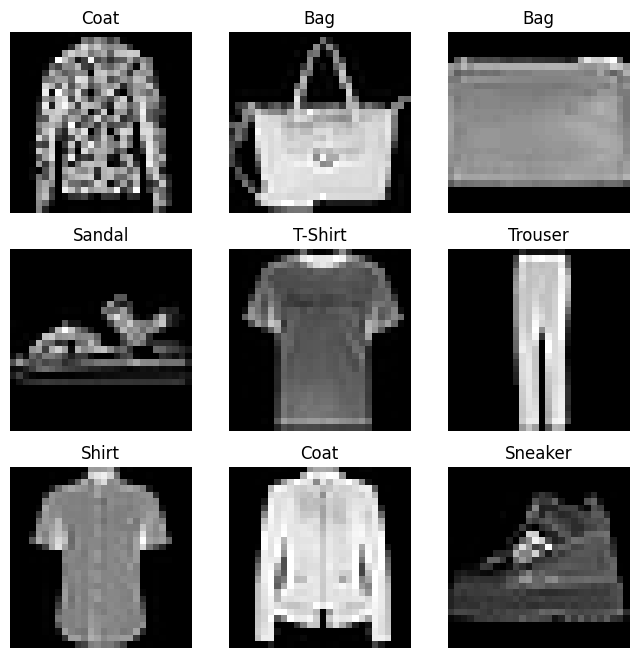

In [74]:
plot_samples(train_data, labels_map, cols=3, rows=3)

Каждый датасет в Pytorch должен наследоваться от класса Dataset и обязательно имплементировать методы `__init__, __len__, __getitem__`. В `__init__` обычно кроме прочего определяются трансформации, которые будут применяться к данным. Это может быть преобразование PIL.Image в тензоры, добавление шума, сдвиги и т.д. 
Pytorch предоставляет большое количество трансформаций, но наиболее популярная и удобная библиотека, реализующая трансформации для изображений - *albumentations*. 

`__len__` - должна возвращать размер датасета (например, чисо строк в файле с аннотациями)

`__getitem__` - должен возвращать семпл данных, например, вектор признаков и y. Однако он может возвращать еще и дополнительную информацию, например, y может состоять из набора bboxoв и  сегментационных масок для детекции, класса изображения итп. Обычно возвращается tuple. В целом, возвращаться может любая структура, которую можно представить как набор тензоров, соответствующих одному семплу и входу модели.
Внутри этого метода может происходить загрузка семпла, его трансформации и другие необходимые манипуляции. Очевидно, что он может возвращать не только изображение, но и любые другие данные, и временные ряды, и табличные данные, и облака точек, и другое. 


Давайте реализуем такой датасет для FashionMNIST. Конечно, можно было бы спокойно использовать встроенный, но так не интересно )

In [75]:
from torchvision.datasets.mnist import read_image_file, read_label_file

In [76]:
class FashionMNISTDataset(Dataset):
    def __init__(self, file_dir, train=True, transform=None, target_transform=None):
        self.transform = transform
        self.target_transform = target_transform
        self.train = train
        image_file = f"{'train' if self.train else 't10k'}-images-idx3-ubyte"
        self.data = read_image_file(os.path.join(file_dir, image_file))

        label_file = f"{'train' if self.train else 't10k'}-labels-idx1-ubyte"
        self.targets = read_label_file(os.path.join(file_dir, label_file))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx]
        label = self.targets[idx]
        
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

Проинициализируйте ваш новый датасет так же, как и ранее встроенный.

In [77]:
def as_image_tensor(image):
    # read_image_file отдаёт uint8 (H, W). ToTensor делает float (1, H, W) в [0, 1].
    # float() сначала копирует данные: исходный датасет не меняется.
    return image.float().div(255).unsqueeze(0)


raw_dir = os.path.join("data", "FashionMNIST", "raw")
train_data = FashionMNISTDataset(raw_dir, train=True, transform=as_image_tensor)
test_data = FashionMNISTDataset(raw_dir, train=False, transform=as_image_tensor)
train_data[0][0].shape, train_data[0][0].dtype, len(train_data), len(test_data)


(torch.Size([1, 28, 28]), torch.float32, 60000, 10000)

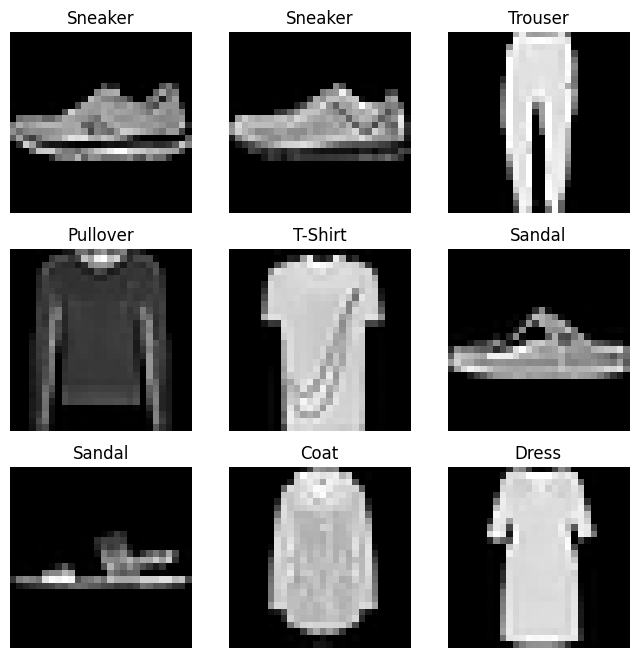

In [78]:
plot_samples(train_data, labels_map, cols=3, rows=3)

Датасет возвращает один семпл за раз, однако часто наши мощности позволяют обрабатывать больше данных. При работе с таблицами модель получает на вход вообще весь набор сразу или достаточно большими порциями. Когда речь заходит о тензорах и наборах с сотнями тысяч и даже миллионами семплов, это невозможно. На помощь приходит батчевая обработка, когда из датасета берутся небольшие порции данных за раз (используя индекс). За соединение семплов во вход модели отвечает класс DataLoader. Каждую эпоху данные шаффлятся, чтобы уменьшить переобучение. 

In [79]:
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


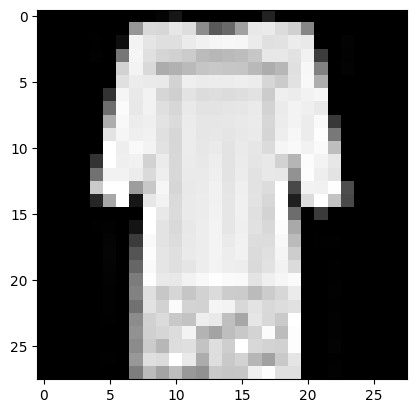

Label: 6


In [80]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze().reshape(28,28)
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

Глубокое обучение чаще всего связывают с GPU, и не зря. Имея дело с тензорами и тензорными вычислениями, мы производим огромное количество элементарных операций. Каждое ядро CPU способно произвести только одно вычисление за такт. GPU был создан для обработки графики, где требуется также большое количество простых вычислений, и поэтому может ускорить обработку данных в тысячи раз. Это все должно быть хорошо Вам известно из других курсов)

К сожалению, часто компьютер не поддерживает вычисления на GPU, например, у него просто нет дискретной видеокарты. Pytorch позволяет проводить все операции на CPU, так что его можно использовать где угодно.



In [81]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


Using cpu device


*Дополнительное задание: адаптируйте весь код для `accelerate`. Это очень удобная библиотека для адаптации PyTorch кода для любой распределенной конфигурации. Кроме того, она позволяет упростить работу, даже если нам нужно перенести вычисления на GPU или CPU, автоматизируя этот процесс (иначе нам нужно постоянно вызывать `.to(device)`)*
*Для этого импортируйте нужный Accelerator из accelerate. Далее достаточно вызвать accelerator.prepare(elements)*

**Решение.** Рабочий вариант цикла на `accelerate` стоит в последнем разделе ноутбука: к тому моменту уже есть модель и функции `train`/`test`, и их не приходится дублировать раньше рассказа про `nn.Module`. `Accelerator.prepare` переносит модель, оптимизатор и батчи на доступное устройство, `accelerator.backward` заменяет `loss.backward()`.


Теперь создадим класс модели и интстанциируем её. В данном случае это простой перцептрон с тремя слоями. Однако модель может быть сколько угодно сложной. Главное, чтобы она наследовала класс `nn.Module`. Более того, можно написать любой слой собственноручно, также отнаследовав этот класс.
Каждая модель должна имплементировать два метода - `__init__` и `forward(self, *args, **kwargs)`. В первом обычно задается ее структура и другие параметры. Модель  может даже содержать другие модели!

`forward` получает на вход Х, но он может получать несколько разных входов, маски и тд. Обычно возвращаются либо выходы с последнего слоя (один или несколько). Но, например, стандартные модели детекции возвращают в режиме обучения значение лосса, а непосредственные предсказания только в режиме тестирования.

Вызывая `model(data)`, на самом деле мы вызываем именно метод `forward`

Для того, чтобы понять, как устроен слой в Pytorch, создадим простой слой для превращения изображения в вектор.
Пусть это будет класс MyFlatten. Изображения (и, что более актуально, промежуточные представления или, иными словами, карты, внутри модели) изначально имеют размер N x C x H x W, где:

N - число семплов в батче
C - число каналов на входе в конкретный слой. Если вход с 3 каналами, это 3, но в середине модели это может быть любое число, например, 128.
H - высота карты
W - ширина карты

Когда мы делаем что-то вроде двумерной свертки, это стандартное представление данных, которое позволяет восстановить пространственные зависимости между элементами карты. Однако, когда мы используем полносвязные модели, каждый семпл представлен единым вектором. В простом случае больше не нужно разделять разные каналы, строки и столбцы данных. Таким образом, мы используем операцию "вытянуть в вектор", чтобы превратить значения C x H x W в представление C * H * W. 

**Задание**: допишите класс MyFlatten. Этот слой при вызове должен принимать на вход тензор размера B x C x H x W и возвращать тензор размера B x [C * H * W]. Пример: батч картинок 2 x 3(rgb) x 16(h) x 16(w)] -> 2 x 768

In [82]:
class MyFlatten(nn.Module):
    # B x C x H x W -> B x (C * H * W). Пример: 2 x 3 x 16 x 16 -> 2 x 768.

    def forward(self, x):
        return x.view(x.size(0), -1)


_check = torch.zeros(2, 3, 16, 16)
assert MyFlatten()(_check).shape == (2, 768)


In [83]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = MyFlatten()
        self.fc = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.fc(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): MyFlatten()
  (fc): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


Слои: http://pytorch.org/docs/nn.html

Активации: http://pytorch.org/docs/nn.html#non-linear-activations

Зададим функцию ошибки и оптимизатор. Функция ошибки также наследуется от torch.nn.Module и может быть стандартной, состоять как из нескольких стандартных функций или их модификаций. Большое количество функций ошибки уже реализовано в Pytorch.

Внутри каждой итерации обучения оптимизация происходит в три этапа:
Вызов optimizer.zero_grad() для обнуления градиентов параметров модели. Градиенты по умолчанию складываются; чтобы избежать двойного подсчета, мы явно обнуляем их на каждой итерации.

Получение градиентов для каждого веса с помощью loss.backward().
Как только мы получили наши градиенты, остается вызвать optimizer.step(), чтобы изменить параметры в соответствии с нашим алгоритмом оптимизации. 

In [84]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Задание: 
1) Выберите как минимум еще 2 разные функции ошибки из https://pytorch.org/docs/stable/nn.html#loss-functions и обучите модель с ними
2) Выберите как минимум еще 1 оптимизатор из https://pytorch.org/docs/stable/optim.html и обучите каждую из моделей с ним

В результате у вас должна получиться таблица с лучшими значениями лосса для каждого случая для обучения и теста. В идеале оформите их в виде pandas.DataFrame или другой таблицы с удобным выводом.

Обучим модель. Для этого нужно описать цикл обучения и проверки модели. В наивном случае создается две функции train и validate (test), которые вызываются в цикле по эпохам. В дальнейшем, при усложнении прохода по эпохе, может появиться метод train, целый класс Trainer и т.д. Пока что реализуем наивный вариант.

In [85]:
def train(dataloader, model, loss_fn, optimizer, verbose=True):
    size = len(dataloader.dataset)
    model.train()
    total_loss = 0.0
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)

        preds = model(inputs)
        loss = loss_fn(preds, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        if verbose and batch_idx % 100 == 0:
            current = (batch_idx + 1) * len(inputs)
            print(f"loss: {loss.item():>7f}  [{current:>5d}/{size:>5d}]")
    return total_loss / len(dataloader)


In [86]:
def macro_precision_recall(pred_labels, true_labels, num_classes=10):
    # Macro: precision и recall считаются по каждому классу и усредняются.
    # Класс без своих предсказаний даёт precision 0, без своих объектов - recall 0.
    precision_sum = 0.0
    recall_sum = 0.0
    for cls in range(num_classes):
        true_positive = ((pred_labels == cls) & (true_labels == cls)).sum().item()
        false_positive = ((pred_labels == cls) & (true_labels != cls)).sum().item()
        false_negative = ((pred_labels != cls) & (true_labels == cls)).sum().item()
        precision_sum += (
            true_positive / (true_positive + false_positive)
            if true_positive + false_positive
            else 0.0
        )
        recall_sum += (
            true_positive / (true_positive + false_negative)
            if true_positive + false_negative
            else 0.0
        )
    return precision_sum / num_classes, recall_sum / num_classes


def test(dataloader, model, loss_fn, verbose=True):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, num_correct = 0.0, 0.0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            preds = model(inputs)
            test_loss += loss_fn(preds, targets).item()
            predicted = preds.argmax(1)
            num_correct += (predicted == targets).sum().item()
            all_preds.append(predicted.cpu())
            all_targets.append(targets.cpu())
    test_loss /= num_batches
    accuracy = num_correct / size
    precision, recall = macro_precision_recall(torch.cat(all_preds), torch.cat(all_targets))
    if verbose:
        print(
            f"Test Error: \n Accuracy: {(100 * accuracy):>0.1f}%, "
            f"Precision: {precision:.3f}, Recall: {recall:.3f}, "
            f"Avg loss: {test_loss:>8f} \n"
        )
    return test_loss, accuracy, precision, recall


Задание: Добавьте метрики precision и recall для проверки

In [87]:
import copy

torch.manual_seed(0)
model = NeuralNetwork().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

epochs = 10
best_state = copy.deepcopy(model.state_dict())
best_acc = 0.0
best_test_loss = float("inf")
best_precision = 0.0
best_recall = 0.0
for t in range(epochs):
    print(f"Epoch {t + 1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test_loss, accuracy, precision, recall = test(test_dataloader, model, loss_fn)
    if accuracy > best_acc:
        best_acc = accuracy
        best_precision = precision
        best_recall = recall
        best_state = copy.deepcopy(model.state_dict())
    best_test_loss = min(best_test_loss, test_loss)

print(
    f"Лучшая accuracy: {100 * best_acc:.1f}% "
    f"(precision {best_precision:.3f}, recall {best_recall:.3f}), "
    f"лучший test loss: {best_test_loss:.4f}"
)


Epoch 1
-------------------------------
loss: 2.300577  [   64/60000]
loss: 2.290688  [ 6464/60000]
loss: 2.267696  [12864/60000]
loss: 2.265884  [19264/60000]
loss: 2.253147  [25664/60000]
loss: 2.224884  [32064/60000]
loss: 2.205814  [38464/60000]
loss: 2.224863  [44864/60000]
loss: 2.202589  [51264/60000]
loss: 2.162510  [57664/60000]
Test Error: 
 Accuracy: 50.3%, Precision: 0.504, Recall: 0.503, Avg loss: 2.162530 

Epoch 2
-------------------------------
loss: 2.173475  [   64/60000]
loss: 2.109331  [ 6464/60000]
loss: 2.110880  [12864/60000]
loss: 2.095540  [19264/60000]
loss: 2.016227  [25664/60000]
loss: 2.002687  [32064/60000]
loss: 2.021257  [38464/60000]
loss: 1.979260  [44864/60000]
loss: 1.902756  [51264/60000]
loss: 1.909221  [57664/60000]
Test Error: 
 Accuracy: 59.4%, Precision: 0.515, Recall: 0.594, Avg loss: 1.899051 

Epoch 3
-------------------------------
loss: 1.953929  [   64/60000]
loss: 1.829596  [ 6464/60000]
loss: 1.772546  [12864/60000]
loss: 1.809427  [192

Осталось сохранить модель для дальнейшего использования. 

In [88]:
torch.save(best_state, "best_model.pth")
print(f"Сохранены веса лучшей эпохи, accuracy {100 * best_acc:.1f}%")


Сохранены веса лучшей эпохи, accuracy 71.5%


Какая точность получилась?

**Ответ.** 71.5% accuracy на тесте (macro precision 0.717, macro recall 0.715), лучший средний test loss 0.779. Это SGD, `lr=1e-3`, 10 эпох, seed 0. Сеть уже отделяет часть классов одежды, но близкие вещи вроде рубашки, пальто и пуловера путает: для сырых пикселей и маленького шага SGD это ожидаемый уровень за такой короткий прогон.


### Сравнение функций ошибки и оптимизаторов

Берутся три функции ошибки и два оптимизатора, у каждого запуска 5 эпох и одинаковый `lr=1e-3`, seed фиксирован.

- `CrossEntropyLoss` — основной лосс для логитов.
- `NLLLoss` сам по себе ждёт логарифмы вероятностей. Обёртка применяет `log_softmax`, поэтому численно это та же кросс-энтропия.
- `MultiMarginLoss` штрафует недостаточный зазор между верным классом и остальными. Шкала другого порядка, чем у кросс-энтропии, поэтому строки таблицы сравниваются по accuracy, а не по величине loss.

В таблице — минимальный средний loss за эпоху на train и на test и лучшая test accuracy.

In [89]:

class NLLFromLogits(nn.Module):
    def forward(self, logits, targets):
        return nn.functional.nll_loss(nn.functional.log_softmax(logits, dim=1), targets)


def run_experiment(criterion, optimizer_name, epochs=5, lr=1e-3):
    torch.manual_seed(0)
    exp_model = NeuralNetwork().to(device)
    if optimizer_name == "SGD":
        exp_optimizer = torch.optim.SGD(exp_model.parameters(), lr=lr)
    elif optimizer_name == "Adam":
        exp_optimizer = torch.optim.Adam(exp_model.parameters(), lr=lr)
    else:
        raise ValueError(optimizer_name)

    best_train = float("inf")
    best_test = float("inf")
    best_accuracy = 0.0
    for _ in range(epochs):
        train_loss = train(train_dataloader, exp_model, criterion, exp_optimizer, verbose=False)
        test_loss, accuracy, _, _ = test(test_dataloader, exp_model, criterion, verbose=False)
        best_train = min(best_train, train_loss)
        best_test = min(best_test, test_loss)
        best_accuracy = max(best_accuracy, accuracy)
    return {
        "loss": criterion.__class__.__name__,
        "optimizer": optimizer_name,
        "best_train_loss": best_train,
        "best_test_loss": best_test,
        "best_test_accuracy": best_accuracy,
    }


rows = []
for criterion in (nn.CrossEntropyLoss(), NLLFromLogits(), nn.MultiMarginLoss()):
    for optimizer_name in ("SGD", "Adam"):
        print(criterion.__class__.__name__, optimizer_name)
        rows.append(run_experiment(criterion, optimizer_name))

loss_comparison = pd.DataFrame(rows)
loss_comparison


CrossEntropyLoss SGD
CrossEntropyLoss Adam
NLLFromLogits SGD
NLLFromLogits Adam
MultiMarginLoss SGD
MultiMarginLoss Adam


,loss,optimizer,best_train_loss,best_test_loss,best_test_accuracy
0,CrossEntropyLoss,SGD,1.146991,1.075410,0.6488
1,CrossEntropyLoss,Adam,0.277473,0.353754,0.8696
2,NLLFromLogits,SGD,1.146991,1.075410,0.6488
3,NLLFromLogits,Adam,0.277473,0.353754,0.8696
4,MultiMarginLoss,SGD,0.226548,0.213451,0.6522
5,MultiMarginLoss,Adam,0.035615,0.046478,0.8723


Задание: Перепишите датасет FashionMNISTDataset так, чтобы он возвращал вектор вместо матрицы и мою модель без слоя MyFlatten(). Запустите обучение заново. Какая точность получилась теперь?

Задание: придумайте свою собственную модель. Улучшите результат (но без сверток)

**Решение.** Базовый MLP со SGD и `lr=1e-3` за 10 эпох недобучивается: шаг одинаковый у всех весов и довольно маленький. Ниже сеть без свёрток: Linear -> BatchNorm -> GELU -> Dropout, к выходу уже. BatchNorm держит масштаб активаций, Dropout мешает запомнить конкретные пиксели обучающей выборки, Adam задаёт свой шаг каждой координате.

По совету из ячейки про гиперпараметры валидация отделена от теста: 6 000 объектов взяты из train, по ним выбирается лучшая эпоха, тест считается один раз в конце.

In [90]:

class MyNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = MyFlatten()
        self.net = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.GELU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(self.flatten(x))


val_size = 6_000
train_size = len(train_data) - val_size
train_split, val_split = torch.utils.data.random_split(
    train_data,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(0),
)
train_split_loader = DataLoader(train_split, batch_size=64, shuffle=True)
val_loader = DataLoader(val_split, batch_size=64)

torch.manual_seed(0)
my_model = MyNetwork().to(device)
my_optimizer = torch.optim.Adam(my_model.parameters(), lr=1e-3)
my_loss = nn.CrossEntropyLoss()
my_best_state = copy.deepcopy(my_model.state_dict())
my_best_val = 0.0
for epoch in range(10):
    train(train_split_loader, my_model, my_loss, my_optimizer, verbose=False)
    _, val_acc, val_precision, val_recall = test(val_loader, my_model, my_loss, verbose=False)
    print(
        f"epoch {epoch + 1}: val accuracy={val_acc:.3f} "
        f"precision={val_precision:.3f} recall={val_recall:.3f}"
    )
    if val_acc > my_best_val:
        my_best_val = val_acc
        my_best_state = copy.deepcopy(my_model.state_dict())

my_model.load_state_dict(my_best_state)
_, my_test_acc, my_test_precision, my_test_recall = test(
    test_dataloader, my_model, my_loss, verbose=False
)
print(
    f"Своя модель: лучшая val accuracy {100 * my_best_val:.1f}%, "
    f"test accuracy {100 * my_test_acc:.1f}% "
    f"(precision {my_test_precision:.3f}, recall {my_test_recall:.3f}). "
    f"Базовая модель: {100 * best_acc:.1f}%."
)


epoch 1: val accuracy=0.848 precision=0.856 recall=0.849
epoch 2: val accuracy=0.870 precision=0.876 recall=0.869
epoch 3: val accuracy=0.880 precision=0.884 recall=0.879
epoch 4: val accuracy=0.885 precision=0.885 recall=0.885
epoch 5: val accuracy=0.886 precision=0.886 recall=0.886
epoch 6: val accuracy=0.882 precision=0.888 recall=0.881
epoch 7: val accuracy=0.890 precision=0.890 recall=0.889
epoch 8: val accuracy=0.895 precision=0.896 recall=0.894
epoch 9: val accuracy=0.894 precision=0.897 recall=0.894
epoch 10: val accuracy=0.890 precision=0.891 recall=0.891
Своя модель: лучшая val accuracy 89.5%, test accuracy 88.5% (precision 0.887, recall 0.885). Базовая модель: 71.5%.


При подборе гиперпараметров (это те параметры, которые не обучаются, например, lr) и обучении модели помните:
1. Если параметры выбраны хорошо, улучшение видно уже после нескольких сотен итераций.
2. Настраивайте гиперпараметры от грубых значений к точным: начните с тестирования большого диапазона гиперпараметров всего за несколько итераций обучения, чтобы найти комбинации параметров, которые вообще работают.
3. После того, как вы нашли несколько наборов параметров, которые, по-видимому, работают, выполните более тщательный поиск по этим параметрам. Возможно, вам придется тренировать модель большее число эпох.
4. Нужно использовать валидационный набор для поиска. Этот набор нужно выделить из тренировочного и вызывать на нем функцию test.

Задание: Перепишите датасет FashionMNISTDataset так, чтобы он возвращал вектор вместо матрицы

In [91]:
class FashionMNISTVectorDataset(FashionMNISTDataset):
    # Тот же датасет, но вместо картинки (1, 28, 28) возвращается вектор 784.

    def __getitem__(self, idx):
        image, label = super().__getitem__(idx)
        return image.reshape(-1), label


### Обучение без `MyFlatten`

Датасет отдаёт уже готовый вектор. Модель — тот же трёхслойный перцептрон, вход линейного слоя по-прежнему 784. Ожидание: accuracy близка к базовой, потому что `view` не меняет значения и не добавляет параметров. Отличается только место, где картинка превращается в вектор.

In [92]:

class NeuralNetworkNoFlatten(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.fc(x)


train_vec = FashionMNISTVectorDataset(raw_dir, train=True, transform=as_image_tensor)
test_vec = FashionMNISTVectorDataset(raw_dir, train=False, transform=as_image_tensor)
train_vec_loader = DataLoader(train_vec, batch_size=64, shuffle=True)
test_vec_loader = DataLoader(test_vec, batch_size=64)

torch.manual_seed(0)
flat_model = NeuralNetworkNoFlatten().to(device)
flat_optimizer = torch.optim.SGD(flat_model.parameters(), lr=1e-3)
flat_best_acc = 0.0
for epoch in range(10):
    print(f"Flat epoch {epoch + 1}")
    train(train_vec_loader, flat_model, loss_fn, flat_optimizer, verbose=False)
    _, accuracy, precision, recall = test(test_vec_loader, flat_model, loss_fn, verbose=False)
    flat_best_acc = max(flat_best_acc, accuracy)
    print(f"accuracy={accuracy:.3f}  precision={precision:.3f}  recall={recall:.3f}")

print(f"Лучшая accuracy без MyFlatten: {100 * flat_best_acc:.1f}%")
print(f"Лучшая accuracy базовой модели: {100 * best_acc:.1f}%")


Flat epoch 1
accuracy=0.503  precision=0.504  recall=0.503
Flat epoch 2
accuracy=0.601  precision=0.521  recall=0.601
Flat epoch 3
accuracy=0.617  precision=0.513  recall=0.617
Flat epoch 4
accuracy=0.636  precision=0.556  recall=0.636
Flat epoch 5
accuracy=0.649  precision=0.663  recall=0.649
Flat epoch 6
accuracy=0.657  precision=0.675  recall=0.657
Flat epoch 7
accuracy=0.673  precision=0.685  recall=0.673
Flat epoch 8
accuracy=0.684  precision=0.692  recall=0.684
Flat epoch 9
accuracy=0.697  precision=0.703  recall=0.697
Flat epoch 10
accuracy=0.711  precision=0.715  recall=0.711
Лучшая accuracy без MyFlatten: 71.1%
Лучшая accuracy базовой модели: 71.5%


### `accelerate`

`Accelerator` прячет выбор устройства и перенос батчей. После `prepare` ручные `.to(device)` в обучающем цикле не нужны: батчи уже на том же устройстве, что и модель. `accelerator.backward(loss)` на одной видеокарте делает то же, что `loss.backward()`, а на нескольких процессах ещё и усредняет градиенты. Ниже тот же перцептрон учится две эпохи — этого достаточно, чтобы проверить, что цикл живой.

In [93]:

from accelerate import Accelerator

accelerator = Accelerator()
print("accelerate device:", accelerator.device)

acc_model = NeuralNetwork()
acc_optimizer = torch.optim.Adam(acc_model.parameters(), lr=1e-3)
acc_train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
acc_test_loader = DataLoader(test_data, batch_size=64)
acc_model, acc_optimizer, acc_train_loader, acc_test_loader = accelerator.prepare(
    acc_model, acc_optimizer, acc_train_loader, acc_test_loader
)

acc_loss_fn = nn.CrossEntropyLoss()
for epoch in range(2):
    acc_model.train()
    total_loss = 0.0
    for inputs, targets in acc_train_loader:
        preds = acc_model(inputs)
        loss = acc_loss_fn(preds, targets)
        acc_optimizer.zero_grad()
        accelerator.backward(loss)
        acc_optimizer.step()
        total_loss += loss.item()
    acc_model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, targets in acc_test_loader:
            preds = acc_model(inputs)
            correct += (preds.argmax(1) == targets).sum().item()
            total += targets.size(0)
    print(
        f"accelerate epoch {epoch + 1}: "
        f"train loss {total_loss / len(acc_train_loader):.4f}, "
        f"test accuracy {100 * correct / total:.1f}%"
    )


accelerate device: cpu
accelerate epoch 1: train loss 0.4898, test accuracy 83.7%
accelerate epoch 2: train loss 0.3576, test accuracy 86.6%
